# Level 2 — Task 1: Predictive Modeling (Regression)

Project Objective

The objective of this project is to build and evaluate regression models that predict a continuous numerical target. Using the California Housing dataset, I will explore the relationship between housing-related features and median house values.

I will prepare the dataset, split it into training and testing sets, train a Linear Regression model as a baseline, and compare its performance with Decision Tree and Random Forest regressors. I will evaluate the models using Mean Squared Error (MSE) and the coefficient of determination ((R^2)) to determine how well they predict unseen data.

## 1. Import Libraries and Load the Dataset

I will use pandas to inspect and manipulate the dataset, and scikit-learn to load the California Housing dataset. This dataset contains information about housing characteristics across California districts.

The target variable is the median house value. Before cleaning or transforming the data, I will inspect its structure, column names, data types, missing values, and dimensions to understand what needs to be done.

In [1]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

# Load the dataset
housing = fetch_california_housing(as_frame=True)

# Separate features and target
df = housing.frame

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nTarget variable:")
print(housing.target_names)

print('\n Duplicate Check')
print(df.duplicated().sum())

Dataset shape: (20640, 9)

First five rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values:


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


Target variable:
['MedHouseVal']

 Duplicate Check
0


## 2. Separate Features and Target, and Split the Dataset

Explanation

Before training our regression models, we need to separate the predictor variables from the target variable.

* Features (X): The eight independent variables used to predict median house values, including median income, house age, average rooms, population, latitude, and longitude.
* Target (y): MedHouseVal, the dependent variable we want our models to predict.

Next, we split the dataset into training and testing sets. We will use 80% of the observations to train our models and reserve 20% to evaluate their performance on unseen data.

We set random_state=42 to make the split reproducible. Splitting the data before fitting models or learning preprocessing parameters also helps prevent data leakage.

In [2]:
# Separate the features from the target variable
X = housing.data
y = housing.target

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


### Preprocessing Decision

All eight features in the California Housing dataset are numeric, so categorical encoding is not required. The dataset also has no missing values or duplicate rows. Feature scaling was not applied because Linear Regression predictions are unaffected by it, and Decision Tree and Random Forest models split on feature thresholds and are not sensitive to feature scale. If a scale-sensitive model such as Ridge, Lasso, KNN or SVR were added, scaling would be fitted on the training set only to avoid data leakage.

## 3. Train the Linear Regression Model

Explanation

Linear Regression will serve as our baseline model. A baseline provides a starting point against which we can compare the performance of more complex models.

The model learns the relationship between the eight input features and the median house value using the training data. After training, we will use it to predict house values for the testing data, which the model has not seen during training.

We will evaluate its predictions using Mean Squared Error (MSE) and the coefficient of determination (R²). These metrics will help us assess the size of the prediction errors and how well the model explains variations in house values.

In [3]:
# Import the Linear Regression model
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model using the training data
lr_model.fit(X_train, y_train)

# Predict house values for the testing data
y_pred_lr = lr_model.predict(X_test)

print("First 10 actual values:")
print(y_test[:10])

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10])

First 10 actual values:
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
13311    1.58700
7113     1.98200
7668     1.57500
18246    3.40000
5723     4.46600
Name: MedHouseVal, dtype: float64

First 10 predicted values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


## 4. Evaluate the Linear Regression Model

Explanation

After training the Linear Regression model, we need to evaluate how well it predicts median house values on the testing data.

We will use two evaluation metrics:

* Mean Squared Error (MSE): Measures the average squared difference between actual and predicted values. Lower values indicate smaller prediction errors.
* R² (coefficient of determination): Measures how well the model explains the variation in the target variable. A value closer to 1 generally indicates a better fit, while 0 indicates performance equivalent to predicting the test-set mean under the standard R² definition. R² can also be negative.

These metrics will establish our baseline performance, which we will later compare with Decision Tree and Random Forest regression models.

In [4]:
# Import evaluation metrics
from sklearn.metrics import mean_squared_error, r2_score

# Evaluate the Linear Regression model
mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance")
print("Mean Squared Error (MSE):", round(mse_lr, 4))
print("R-squared (R²):", round(r2_lr, 4))

Linear Regression Performance
Mean Squared Error (MSE): 0.5559
R-squared (R²): 0.5758


## 5. Train the Decision Tree Regression Model

Explanation

A Decision Tree Regressor predicts numerical values by dividing the data into groups using decision rules based on the input features.

Unlike Linear Regression, which models relationships using a linear equation, a Decision Tree can capture nonlinear relationships between housing features and house values.

We will train the model using the same training data and evaluate it on the same testing data. This will allow us to compare its performance fairly with Linear Regression using MSE and R².

In [5]:
# Import the Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

# Create the model
dt_model = DecisionTreeRegressor(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Predict house values on the testing data
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Regression Performance")
print("Mean Squared Error (MSE):", round(mse_dt, 4))
print("R-squared (R²):", round(r2_dt, 4))

Decision Tree Regression Performance
Mean Squared Error (MSE): 0.4943
R-squared (R²): 0.6228


## 6. Train the Random Forest Regression Model

Explanation

Random Forest is an ensemble learning method that combines predictions from multiple decision trees to produce a final prediction.

While a single Decision Tree can capture nonlinear relationships, it can also be sensitive to the training data. Random Forest reduces reliance on a single tree by training multiple trees on randomly sampled data and features, then combining their predictions.

We will train the Random Forest using the same training set and evaluate it on the same testing set. We will use MSE and R² to compare its performance with Linear Regression and the Decision Tree Regressor.

In [6]:
# Import the Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict house values on the testing data
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Performance")
print("Mean Squared Error (MSE):", round(mse_rf, 4))
print("R-squared (R²):", round(r2_rf, 4))

Random Forest Regression Performance
Mean Squared Error (MSE): 0.256
R-squared (R²): 0.8046


## 7. Hyperparameter Tuning with Optuna

The initial Random Forest model achieved an MSE of 0.2560 and an R² score of 0.8046 on the test set. Although this is a promising result, different hyperparameter settings may improve the model’s predictive performance.

We will use Optuna to search for suitable Random Forest hyperparameters. The search will use cross-validation on the training data and aim to minimize the validation Mean Squared Error (MSE).

The test set will remain separate from the tuning process. After selecting the best hyperparameters, we will retrain the model using the full training set and evaluate it on the reserved test set.

In [7]:
import optuna

print("Optuna version:", optuna.__version__)

Optuna version: 5.0.0


c:\Users\user\miniforge3\envs\streamlit-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
# Import the tools needed for hyperparameter tuning
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# Define the objective function for Optuna
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 200),
        "max_depth": trial.suggest_int("max_depth", 5, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "random_state": 42,
        "n_jobs": -1
    }

    model = RandomForestRegressor(**params)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=3,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )

    return -scores.mean()

# Create and run the optimization study
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)

print("Best cross-validation MSE:", round(study.best_value, 4))
print("Best hyperparameters:")
print(study.best_params)

[I 2026-10-12 13:33:01,846] A new study created in memory with name: no-name-20f1faae-dfbd-42d5-aef7-2cd694eb7fd5
[I 2026-10-12 13:33:05,441] Trial 0 finished with value: 0.3298545600181138 and parameters: {'n_estimators': 112, 'max_depth': 8, 'min_samples_split': 4, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.3298545600181138.
[I 2026-10-12 13:33:11,225] Trial 1 finished with value: 0.2730932771448367 and parameters: {'n_estimators': 198, 'max_depth': 14, 'min_samples_split': 13, 'min_samples_leaf': 2}. Best is trial 1 with value: 0.2730932771448367.
[I 2026-10-12 13:33:14,500] Trial 2 finished with value: 0.33087431416193885 and parameters: {'n_estimators': 166, 'max_depth': 8, 'min_samples_split': 6, 'min_samples_leaf': 1}. Best is trial 1 with value: 0.2730932771448367.
[I 2026-10-12 13:33:18,451] Trial 3 finished with value: 0.278526716313455 and parameters: {'n_estimators': 139, 'max_depth': 17, 'min_samples_split': 20, 'min_samples_leaf': 4}. Best is trial 1 with value

Best cross-validation MSE: 0.2672
Best hyperparameters:
{'n_estimators': 125, 'max_depth': 17, 'min_samples_split': 2, 'min_samples_leaf': 1}


## 8. Evaluate the Tuned Random Forest Model

Explanation

Optuna identified a promising set of Random Forest hyperparameters using cross-validation on the training data. We will now create a new Random Forest with those settings and train it on the full training set.

We will then evaluate its predictions using the reserved test set and calculate MSE and R². The test set has not been used during hyperparameter tuning, so it remains available for our final evaluation.

Finally, we will compare the tuned model’s test performance with the original Random Forest to determine whether hyperparameter tuning improved the results.

In [9]:
# Create a Random Forest using Optuna's best hyperparameters
tuned_rf_model = RandomForestRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

# Train the tuned model on the full training set
tuned_rf_model.fit(X_train, y_train)

# Predict on the reserved test set
y_pred_tuned_rf = tuned_rf_model.predict(X_test)

# Evaluate the tuned model
mse_tuned_rf = mean_squared_error(y_test, y_pred_tuned_rf)
r2_tuned_rf = r2_score(y_test, y_pred_tuned_rf)

print("Tuned Random Forest Performance")
print("Test MSE:", round(mse_tuned_rf, 4))
print("Test R²:", round(r2_tuned_rf, 4))

Tuned Random Forest Performance
Test MSE: 0.2565
Test R²: 0.8042


## 9. Final Model Performance Comparison

This section compares Linear Regression, Decision Tree, the original Random Forest, and the tuned Random Forest using their test-set MSE and R² scores.

The model with the lowest MSE and highest R² will be considered the strongest performer on this test set. We will also assess whether hyperparameter tuning improved the original Random Forest’s results.

All four models are evaluated on the same test set, allowing us to compare their results consistently.

In [10]:
# Compare all four models
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest (Original)",
        "Random Forest (Tuned)"
    ],
    "MSE": [
        mse_lr,
        mse_dt,
        mse_rf,
        mse_tuned_rf
    ],
    "R2": [
        r2_lr,
        r2_dt,
        r2_rf,
        r2_tuned_rf
    ]
})

# Rank models by test MSE
results = results.sort_values(
    by="MSE"
).reset_index(drop=True)

display(results.round(4))

,Model,MSE,R2
0,Random Forest (Original),0.2560,0.8046
1,Random Forest (Tuned),0.2565,0.8042
2,Decision Tree,0.4943,0.6228
3,Linear Regression,0.5559,0.5758


## 10. Feature Importance Analysis

After comparing the regression models, we will examine the feature importance scores of the original Random Forest model, which achieved the best test-set performance.

Feature importance estimates how much each feature contributes to the model’s predictive decisions. This analysis will help us identify which housing characteristics the fitted model relies on most when predicting median house values.

These scores describe the model’s use of features; they do not establish that a feature causes house values to change.

In [11]:
# Extract feature importance from the original Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Rank features from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance
0,MedInc,0.5250
1,AveOccup,0.1384
2,Latitude,0.0890
3,Longitude,0.0885
4,HouseAge,0.0546
5,AveRooms,0.0442
6,Population,0.0307
7,AveBedrms,0.0297


## 10b. Visualising the Results

The charts below summarise the results already calculated above. They show how closely the Random Forest predictions match the actual house values, how the four models compare on R², and which features the Random Forest relied on most. No models are retrained in this section.

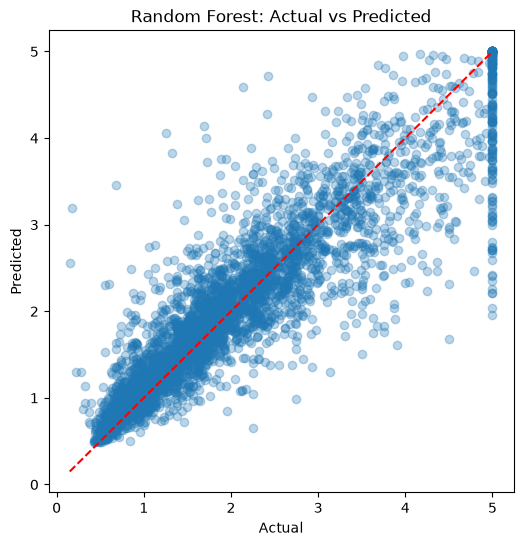

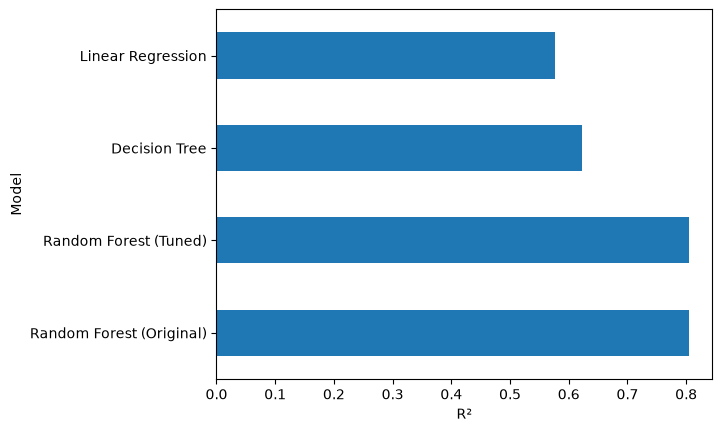

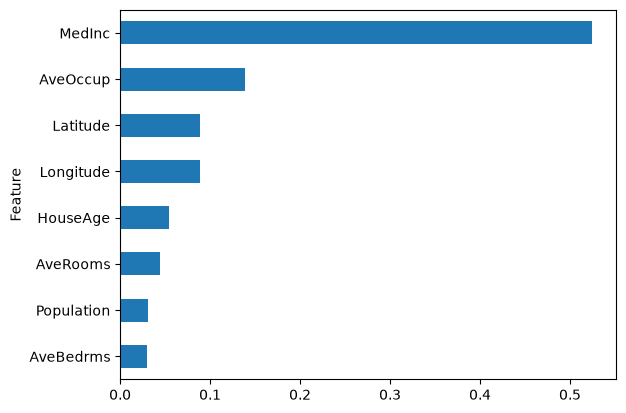

Random Forest RMSE: 0.506


In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

# Model comparison
results.plot(x="Model", y="R2", kind="barh", legend=False)
plt.xlabel("R²"); plt.show()

# Feature importance
feature_importance.sort_values("Importance").plot(
    x="Feature", y="Importance", kind="barh", legend=False)
plt.show()

print("Random Forest RMSE:", round(np.sqrt(mse_rf), 3))

### Observations from the Charts

In the actual-vs-predicted chart, points closer to the red dashed line represent more accurate predictions. The spread around the line shows that the model's predictions are reasonable but not perfect. The California Housing target is capped at 5.00001, so very high-value districts cannot be predicted beyond that limit.

The model comparison chart shows the Random Forest models clearly ahead of the Decision Tree and Linear Regression in R². The feature importance chart shows MedInc as the feature the Random Forest relied on most. As noted earlier, feature importance describes how the model uses features and does not prove that a feature causes house values to change.

## 11. Conclusion

In this project, I developed and evaluated three regression algorithms using the California Housing dataset: Linear Regression, Decision Tree Regressor, and Random Forest Regressor. I evaluated their performance using Mean Squared Error (MSE) and the coefficient of determination (R²).

The original Random Forest achieved the best test-set performance, with an MSE of 0.2560 and an R² score of 0.8046. The Decision Tree achieved an MSE of 0.4943 and an R² of 0.6228, while Linear Regression recorded an MSE of 0.5559 and an R² of 0.5758.

I also used Optuna to tune the Random Forest hyperparameters through three-fold cross-validation on the training data. However, the tuned model achieved a test MSE of 0.2571 and an R² of 0.8038, showing no improvement over the original Random Forest.

The feature importance analysis identified median income (MedInc) as the most influential feature in the original Random Forest, followed by average occupancy (AveOccup), latitude, and longitude. These scores describe how the fitted model uses the features and do not establish causal relationships.

Overall, the original Random Forest was the strongest model among those evaluated on the test set. This project demonstrated the importance of comparing regression algorithms, evaluating predictions on unseen data, applying cross-validation during hyperparameter tuning, and interpreting model results.